# P3.1 · ShopDirect: кого да включим в следващата кампания?

**Курсова работа по маркетингов анализ · Модули 06–07**  
**Студент:** Илияна Цанова · **Факултетен №:** 252042 · **Специалност:** Маркетинг  
**Инструменти:** Python · логистична регресия · Random Forest  
**Изходен набор:** `P3_1_campaign_response.csv` — предоставен от преподавателя.

> **Решение накратко.** На историческите данни логистичната регресия има малко по-добри резултати от разгледания Random Forest (ROC AUC **0,774** срещу **0,756** върху тестовата извадка). Разликата е **несигурна**, затова предпочитанието за логистичния модел се основава и на неговата по-лесна интерпретация. При **примерен капацитет от 30%** моделът подбира 60 от 200 тестови клиенти, като 37 от тях са отговорили положително (**61,7%** срещу **33,0%** обща честота; **1,87× lift**).

**Важно разграничение:** Това е анализ на *вероятността за отговор* към историческа оферта. Той не доказва, че новата оферта ще доведе до допълнителни покупки, нито определя оптимален бюджет.


## 1. Маркетингов проблем и управленски въпрос

ShopDirect разполага с информация за поведението на 800 клиента и за това дали са отговорили на предишна кампания. Ако следващата кампания има ограничен капацитет за комуникация, възниква практичен въпрос: **на кои клиенти да изпратим предложението първо?**

За отговор използваме седемте налични клиентски характеристики, за да оценим `P(response = Yes)`. Сравняваме два класификационни модела, а след това ранжираме клиентите според прогнозната им вероятност. Моделът служи за **избор на аудитория**. Конкретното съдържание на индивидуалната оферта изисква допълнителна информация, например предпочитани продуктови категории и стойност на отстъпката, каквато тук няма.

**Критерий за управленски избор:** добра способност за ранжиране, разбираеми резултати, възможност за изпълнение и измерване чрез пилотна кампания.


## 2. Аналитичен подход и възпроизводимост

- **Наблюдение:** един клиент; `response` е двоичен резултат (`Yes=1`, `No=0`). `customer_id` се използва само като идентификатор.
- **Разделяне:** 600 клиента за обучение (75%) и 200 за независим тест (25%), със стратификация и фиксирано случайно състояние `42`.
- **Проверка на модели:** 5-кратна стратифицирана кръстосана проверка (**само върху обучаващата извадка**), след която моделите се оценяват върху същата тестова извадка.
- **Методи:** логистична регресия (със стандартизация на числовите показатели) и Random Forest; обработката на данните е вътре в `Pipeline`, за да не се използват тестови статистики при обучение.
- **Метрики:** ROC AUC за ранжиране, Accuracy / Sensitivity / Specificity при праг 0,50 и Brier score за качеството на вероятностните прогнози. Самият Brier score **не доказва добра калибрация**, затова добавяме и диагностична крива.
- **Бизнес правило:** разглеждаме обхват от 20%, 30% и 40% от тестовата аудитория. **30% се приема като илюстративно ограничение на ресурсите**, а не като доказан икономически оптимум. Резултатите за този сценарий са проучвателни.
- **Устойчивост:** допълнителен bootstrap анализ на тестовите прогнозни вероятности (2000 повторения) показва как несигурността влияе на разликата в AUC; това не замества бъдеща валидация.

Няма предоставени времеви маркери, затова не можем да проверим дали седемте предиктора са били измерени **преди** получаването на офертата. Това е важно ограничение, независимо че техническото разделяне train/test е коректно.

**Повторно изпълнение:** Python 3; `pandas`, `numpy`, `scipy`, `matplotlib`, `scikit-learn`, `jupyter`, `nbconvert`. Поставете преподавателския CSV в същата папка и изберете **Run All**. Не са нужни API и външни бази данни.


In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib, sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, roc_auc_score,
                             roc_curve, brier_score_loss)

RANDOM_STATE = 42
NUMERIC_FEATURES = ["website_visits_30d", "orders_12m", "avg_order_value_eur",
                    "recency_days", "email_engagement", "promotion_affinity"]
CATEGORICAL_FEATURES = ["loyalty_member"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
plt.rcParams.update({"figure.figsize": (9, 4.7), "figure.dpi": 120,
                     "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False})
print("Версии:", "Python",sys.version.split()[0], "pandas",pd.__version__,
      "numpy",np.__version__,"scikit-learn",sklearn.__version__)

candidate_paths = [Path('P3_1_campaign_response.csv'),
                   Path('/mnt/data/P3_1_campaign_response.csv')]
data_path = next((p for p in candidate_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError('Поставете P3_1_campaign_response.csv в папката на notebook-а.')
df = pd.read_csv(data_path)

Версии: Python 3.13.5 pandas 2.2.3 numpy 2.3.5 scikit-learn 1.8.0


## 3. Данни и проверка на качеството

Седем предиктора: посещения през последните 30 дни, поръчки за 12 месеца, средна стойност на поръчка (€), дни от последна покупка, email ангажираност, афинитет към промоции и лоялност. Няма дата или идентификатор на кампанията, което ограничава проверката на стабилността във времето.

In [2]:
required_columns = ["customer_id", *FEATURES, "response"]
assert set(required_columns).issubset(df.columns), "Непълна схема."
assert df["customer_id"].is_unique, "Повтарящи се клиентски ID."
assert set(df["response"].dropna().unique()) <= {"Yes", "No"}
assert set(df["loyalty_member"].dropna().unique()) <= {"Yes", "No"}
assert not df[required_columns].isna().any().any(), "Наличие на липсващи стойности."
assert all(df[col].ge(0).all() for col in NUMERIC_FEATURES)
assert all(df[col].between(0,1).all() for col in ['email_engagement','promotion_affinity'])
y = df['response'].eq('Yes').astype(int)
quality = pd.DataFrame({"Проверка": ["Клиенти", "Уникални ID", "Липсващи клетки",
                                      "Положителни отговори", "Отрицателни отговори", "Response rate"],
                        "Резултат": [len(df),df.customer_id.nunique(),int(df.isna().sum().sum()),
                                     int(y.sum()),int((1-y).sum()),f"{y.mean():.1%}"]})
display(quality)

,Проверка,Резултат
0,Клиенти,800
1,Уникални ID,800
2,Липсващи клетки,0
3,Положителни отговори,264
4,Отрицателни отговори,536
5,Response rate,33.0%


In [3]:
descriptive = df[NUMERIC_FEATURES].agg(['mean','median','std','min','max']).T
numeric_names = {"website_visits_30d":"Посещения за 30 дни",
                 "orders_12m":"Поръчки за 12 месеца",
                 "avg_order_value_eur":"Средна поръчка (€)",
                 "recency_days":"Дни от последна покупка",
                 "email_engagement":"Email ангажираност (0–1)",
                 "promotion_affinity":"Промоционален афинитет (0–1)"}
descriptive.index = descriptive.index.map(numeric_names)
display(descriptive.rename(columns={'mean':'Средно','median':'Медиана','std':'Ст. откл.',
                                     'min':'Мин.','max':'Макс.'}).round(2))

,Средно,Медиана,Ст. откл.,Мин.,Макс.
Посещения за 30 дни,6.05,6.00,2.22,1.00,16.00
Поръчки за 12 месеца,1.95,2.00,1.44,0.00,8.00
Средна поръчка (€),72.57,72.79,24.12,15.00,151.83
Дни от последна покупка,26.97,23.00,17.87,1.00,100.00
Email ангажираност (0–1),0.37,0.37,0.16,0.02,0.90
Промоционален афинитет (0–1),0.48,0.47,0.20,0.02,0.95


## 4. Какво се вижда в описателните данни?

**Таблица 1 и Фигура 1.** Положително са отговорили **264 от 800** клиента, или **33,0%**. Това е базовият ориентир за оценката на таргетираните групи, а не резултат от бъдеща кампания.


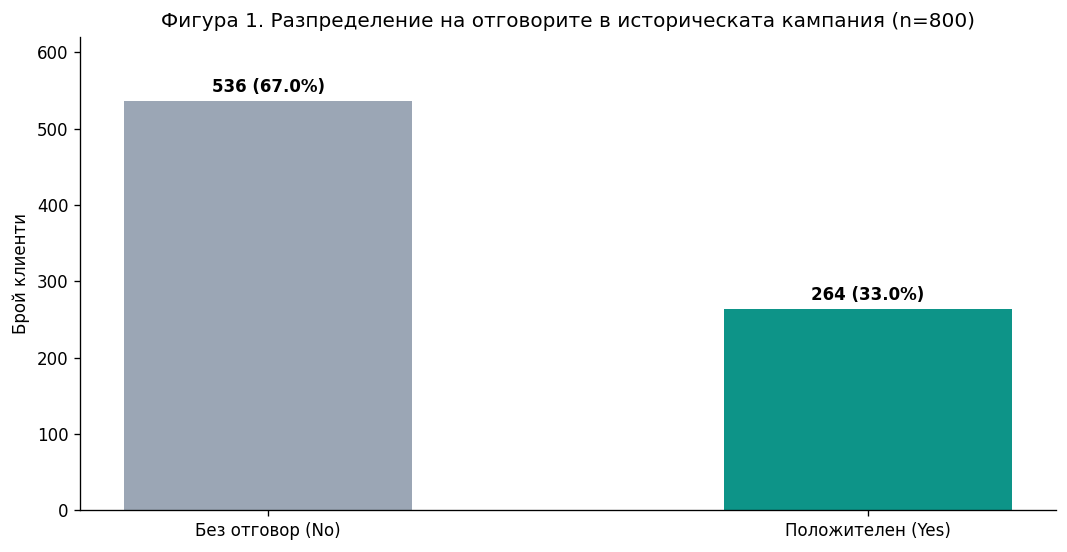

In [4]:
fig, ax = plt.subplots()
counts = y.value_counts().reindex([0,1])
bars=ax.bar(['Без отговор (No)','Положителен (Yes)'],counts.values,color=['#9ba6b5','#0d9488'],width=.48)
ax.set(ylabel='Брой клиенти',title='Фигура 1. Разпределение на отговорите в историческата кампания (n=800)')
ax.set_ylim(0,620)
for b, n in zip(bars,counts): ax.text(b.get_x()+b.get_width()/2,b.get_height()+12,f'{n} ({n/len(df):.1%})',ha='center',weight='bold')
plt.tight_layout();plt.show()

**Таблица 2 и Фигура 2.** При членовете на програмата за лоялност честотата на отговор е **42,5%**, а при останалите — **25,1%**. Разликата е описателна: не можем да заключим, че самото членство е причината за отговора.


,Клиенти,Положителни,Дял
loyalty_member,,,
Не е член,438,110,25.1%
Член,362,154,42.5%


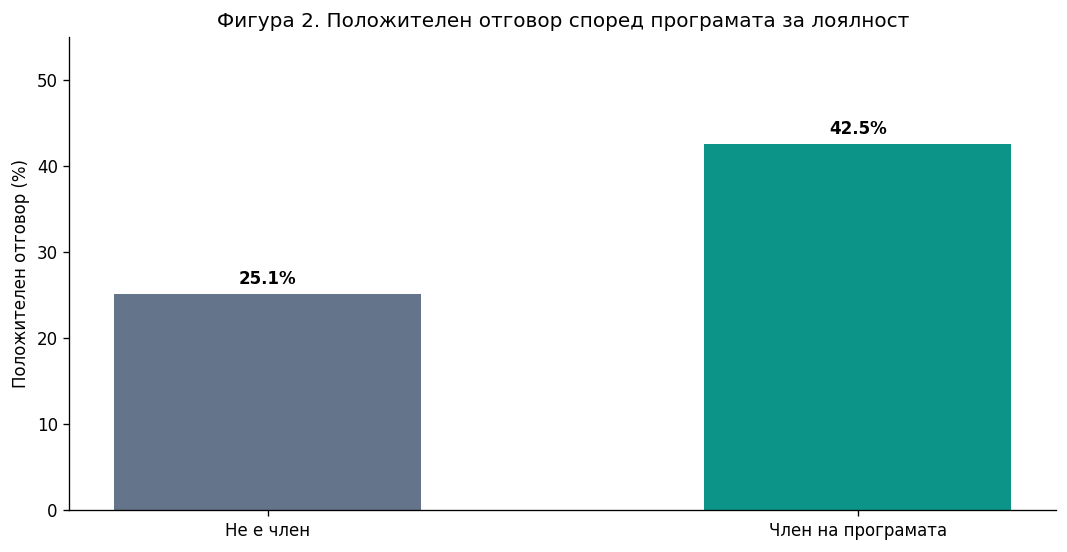

In [5]:
loyalty_tab=(df.assign(response_binary=y).groupby('loyalty_member')
             .agg(Клиенти=('response_binary','size'), Положителни=('response_binary','sum'),
                  Дял=('response_binary','mean')).reindex(['No','Yes']))
display(loyalty_tab.rename(index={'No':'Не е член','Yes':'Член'}).style.format({'Дял':'{:.1%}'}))
fig,ax=plt.subplots()
vals=loyalty_tab['Дял'].values
bars=ax.bar(['Не е член','Член на програмата'],vals*100,color=['#64748b','#0d9488'],width=.52)
ax.set(title='Фигура 2. Положителен отговор според програмата за лоялност',ylabel='Положителен отговор (%)',ylim=(0,55))
for b,v in zip(bars,vals): ax.text(b.get_x()+b.get_width()/2,b.get_height()+1.2,f'{v:.1%}',ha='center',weight='bold')
plt.tight_layout();plt.show()

**Фигура 3.** Сравняваме честотата на отговор по четири приблизително еднакво големи групи за посещенията и дните от последната покупка. Използвани са рангове; равни стойности могат да попаднат в съседни групи. Фигурата показва тенденция, но не отчита едновременно останалите характеристики.


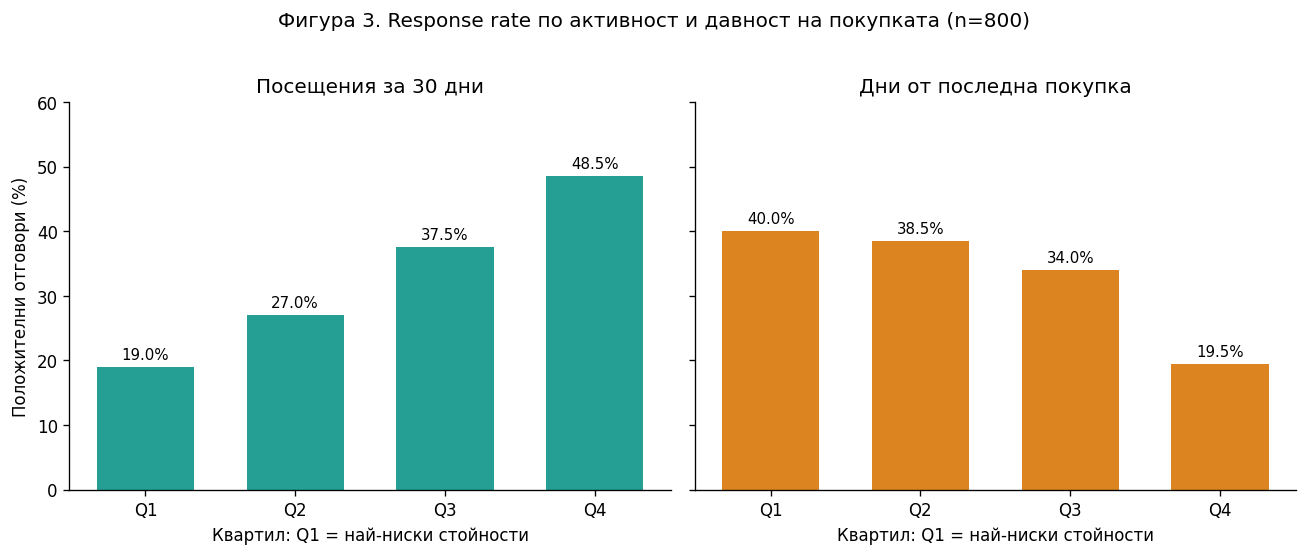

In [6]:
def rank_quartile_response(feature):
    bins = pd.qcut(df[feature].rank(method='first'),4,labels=['Q1','Q2','Q3','Q4'])
    return df.assign(quartile=bins, yes=y).groupby('quartile',observed=False)['yes'].agg(['size','mean'])
quartile_visits=rank_quartile_response('website_visits_30d')
quartile_recency=rank_quartile_response('recency_days')
fig, axes=plt.subplots(1,2,figsize=(11,4.5),sharey=True)
for ax,tab,title,col in [(axes[0],quartile_visits,'Посещения за 30 дни','#0d9488'),
                          (axes[1],quartile_recency,'Дни от последна покупка','#d97706')]:
    bars=ax.bar(tab.index,tab['mean']*100,color=col,alpha=.9,width=.65)
    ax.set(title=title,xlabel='Квартил: Q1 = най-ниски стойности',ylim=(0,60))
    for b,v in zip(bars,tab['mean']): ax.text(b.get_x()+b.get_width()/2,b.get_height()+1.2,f'{v:.1%}',ha='center',fontsize=9)
axes[0].set_ylabel('Положителни отговори (%)')
fig.suptitle('Фигура 3. Response rate по активност и давност на покупката (n=800)',fontsize=12,y=1.02)
plt.tight_layout();plt.show()

## 5. Моделиране и сравнение

Двата модела се обучават и проверяват при **еднакви условия**. Всички преобразувания са част от `Pipeline`, затова параметрите за стандартизация се определят само от обучаващите данни във всяка итерация. При сравняване на моделите водещ е средният ROC AUC от кръстосаната проверка, а тестовият набор служи за финална проверка.

Random Forest е използван с предварително зададени параметри (`250` дървета, максимална дълбочина `7`, минимум `5` наблюдения в лист), без настройване върху тестовите резултати. Това е сравнение на две конкретни конфигурации, а не доказателство, че логистичната регресия превъзхожда всички възможни горски модели.


In [7]:
X = df[FEATURES].copy()
X_train,X_test,y_train,y_test=train_test_split(X,y,stratify=y,test_size=.25,random_state=RANDOM_STATE)
linear_preprocessor=ColumnTransformer([
    ('num',StandardScaler(),NUMERIC_FEATURES),
    ('cat',OneHotEncoder(drop='if_binary',handle_unknown='ignore'),CATEGORICAL_FEATURES)
])
forest_preprocessor=ColumnTransformer([
    ('num','passthrough',NUMERIC_FEATURES),
    ('cat',OneHotEncoder(drop='if_binary',handle_unknown='ignore'),CATEGORICAL_FEATURES)
])
models={
 'Логистична регресия':Pipeline([('prep',linear_preprocessor),('model',LogisticRegression(max_iter=2000,random_state=RANDOM_STATE))]),
 'Random Forest':Pipeline([('prep',forest_preprocessor),('model',RandomForestClassifier(n_estimators=250,max_depth=7,min_samples_leaf=5,random_state=RANDOM_STATE,n_jobs=-1))])
}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
cv_results={}; test_probabilities={}; model_rows=[]
for name,pipeline in models.items():
    auc_folds=cross_val_score(pipeline,X_train,y_train,scoring='roc_auc',cv=cv)
    cv_results[name]=auc_folds
    pipeline.fit(X_train,y_train)
    proba=pipeline.predict_proba(X_test)[:,1]
    test_probabilities[name]=proba
    pred=(proba>=.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    model_rows.append({'Модел':name,'CV ROC AUC (train)':auc_folds.mean(),
      'Test ROC AUC':roc_auc_score(y_test,proba),
      'Accuracy':accuracy_score(y_test,pred),
      'Sensitivity':tp/(tp+fn), 'Specificity':tn/(tn+fp),
      'Brier score':brier_score_loss(y_test,proba),
      'TP':tp,'FP':fp,'TN':tn,'FN':fn})
comparison=pd.DataFrame(model_rows).set_index('Модел')
display(comparison.style.format({c:'{:.3f}' for c in comparison.columns if c not in ['TP','FP','TN','FN']}))
print('CV folds ROC AUC:', {k:np.round(v,3).tolist() for k,v in cv_results.items()})

,CV ROC AUC (train),Test ROC AUC,Accuracy,Sensitivity,Specificity,Brier score,TP,FP,TN,FN
Модел,,,,,,,,,,
Логистична регресия,0.765,0.774,0.780,0.455,0.940,0.172,30,8,126,36
Random Forest,0.737,0.756,0.745,0.333,0.948,0.182,22,7,127,44


CV folds ROC AUC: {'Логистична регресия': [0.749, 0.774, 0.675, 0.78, 0.846], 'Random Forest': [0.704, 0.751, 0.653, 0.763, 0.813]}


### Базова линия: защо Accuracy не е достатъчна?

Ако без модел приемем, че **никой няма да отговори**, ще получим 67% Accuracy, защото 67% от клиентите действително са в клас `No`. Това обаче дава **нулева чувствителност** — не намираме нито един потенциално отговорил клиент. Поради тази причина оценяваме и ROC AUC, Sensitivity и способността за ранжиране.

In [8]:
majority_baseline = np.zeros(len(y_test), dtype=int)
print(f"Модел 'всички No': Accuracy = {accuracy_score(y_test, majority_baseline):.1%}; "
      f"Sensitivity = 0%; Specificity = 100%; "
      f"ROC AUC = {roc_auc_score(y_test, majority_baseline):.3f}")

Модел 'всички No': Accuracy = 67.0%; Sensitivity = 0%; Specificity = 100%; ROC AUC = 0.500


**Таблица 3.** `Accuracy` е делът правилно класифицирани клиенти. `Sensitivity` измерва каква част от действително отговорилите са открити при праг **0,50**, а `Specificity` — каква част от неотговорилите са разпознати. ROC AUC обобщава ранжирането през всички прагове. По-нисък Brier score показва по-малка средна квадратична грешка на вероятностните прогнози, но **не бива да се тълкува като самостоятелно доказателство за калибрация**.

**Извод:** логистичната регресия е практически предпочитаният модел — има по-висока средна CV ROC AUC (**0,765 срещу 0,737**) и малко по-висока тестова AUC (**0,774 срещу 0,756**). Това преимущество е скромно и зависи от извадката. Не го описваме като категорично статистическо превъзходство.


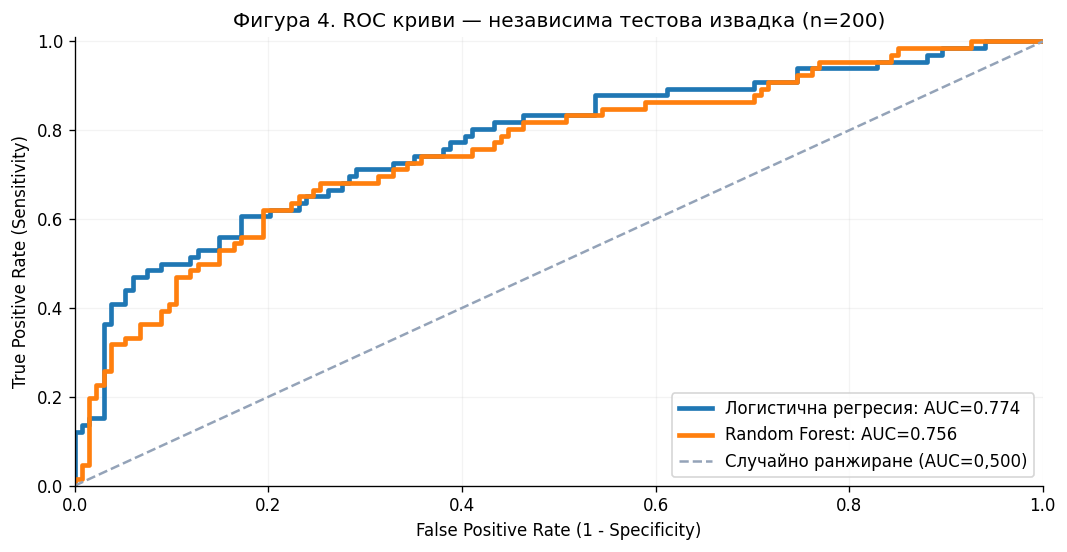

In [9]:
fig,ax=plt.subplots()
for name,proba in test_probabilities.items():
    fpr,tpr,_=roc_curve(y_test,proba)
    ax.plot(fpr,tpr,lw=2.8,label=f'{name}: AUC={roc_auc_score(y_test,proba):.3f}')
ax.plot([0,1],[0,1],'--',color='#94a3b8',label='Случайно ранжиране (AUC=0,500)')
ax.set(xlabel='False Positive Rate (1 - Specificity)',ylabel='True Positive Rate (Sensitivity)',
       title='Фигура 4. ROC криви — независима тестова извадка (n=200)',xlim=(0,1),ylim=(0,1.01))
ax.legend(loc='lower right');ax.grid(alpha=.15)
plt.tight_layout();plt.show()

### 5.1. Колко сигурна е разликата между моделите?

При 200 тестови клиента малката разлика между двата AUC показателя може да зависи от конкретната извадка. Затова преизчисляваме AUC при **2000 повторни избора на тестови редове с връщане** (*bootstrap*). При всяко повторение използваме едни и същи избрани редове за двата модела — така сравнението остава сдвоено. Представяме приблизителен 95% перцентилен интервал, а не формално доказателство, че един модел е по-добър.

In [10]:
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(20261113)
labels = y_test.to_numpy()
prob_log = test_probabilities['Логистична регресия']
prob_forest = test_probabilities['Random Forest']
boot_auc_log, boot_auc_forest, boot_auc_diff = [], [], []
for iteration in range(2000):
    indices = rng.integers(0, len(labels), len(labels))
    observed = labels[indices]
    if observed.min() == observed.max():
        continue
    auc_log = roc_auc_score(observed, prob_log[indices])
    auc_for = roc_auc_score(observed, prob_forest[indices])
    boot_auc_log.append(auc_log)
    boot_auc_forest.append(auc_for)
    boot_auc_diff.append(auc_log - auc_for)
intervals = pd.DataFrame({
    'Показател': ['Логистична регресия: AUC', 'Random Forest: AUC', 'Разлика в AUC (Logistic − Forest)'],
    'Долна 2,5%': [np.quantile(v, .025) for v in [boot_auc_log,boot_auc_forest,boot_auc_diff]],
    'Точкова оценка': [roc_auc_score(labels, prob_log),roc_auc_score(labels,prob_forest),
                      roc_auc_score(labels,prob_log)-roc_auc_score(labels,prob_forest)],
    'Горна 97,5%': [np.quantile(v, .975) for v in [boot_auc_log,boot_auc_forest,boot_auc_diff]]
})
display(intervals.style.format({c:'{:.3f}' for c in intervals.columns if c!='Показател'}))
print('Интервалът за разликата пресича 0:',
      bool(intervals.iloc[2]['Долна 2,5%'] < 0 < intervals.iloc[2]['Горна 97,5%']))

,Показател,"Долна 2,5%",Точкова оценка,"Горна 97,5%"
0,Логистична регресия: AUC,0.700,0.774,0.841
1,Random Forest: AUC,0.678,0.756,0.825
2,Разлика в AUC (Logistic − Forest),-0.020,0.018,0.059


Интервалът за разликата пресича 0: True


**Интерпретация на Таблица 4.** Интервалът за разликата в AUC включва **нула** (приблизително от −0,020 до +0,059). Следователно не твърдим сигурна победа. Предпочитанието към логистичната регресия е **прагматично**: подобни или малко по-добри резултати при по-лесно обяснение на маркетинговото решение. Bootstrap интервалите отразяват променливостта на тестовата извадка при вече обучените модели, а не всички източници на неопределеност.

### 5.2. Дали прогнозните вероятности са правдоподобни?

За бизнес таргетиране освен правилен ред на клиентите е важно числото `0,60` да не се тълкува автоматично като гаранция за 60% реакция. Сравняваме средната прогнозна вероятност с действително наблюдавания response rate в пет приблизително равни групи от тестовата извадка. При едва 40 клиента във всяка група това е **ориентировъчна диагноза**, а не доказателство за идеална калибрация.

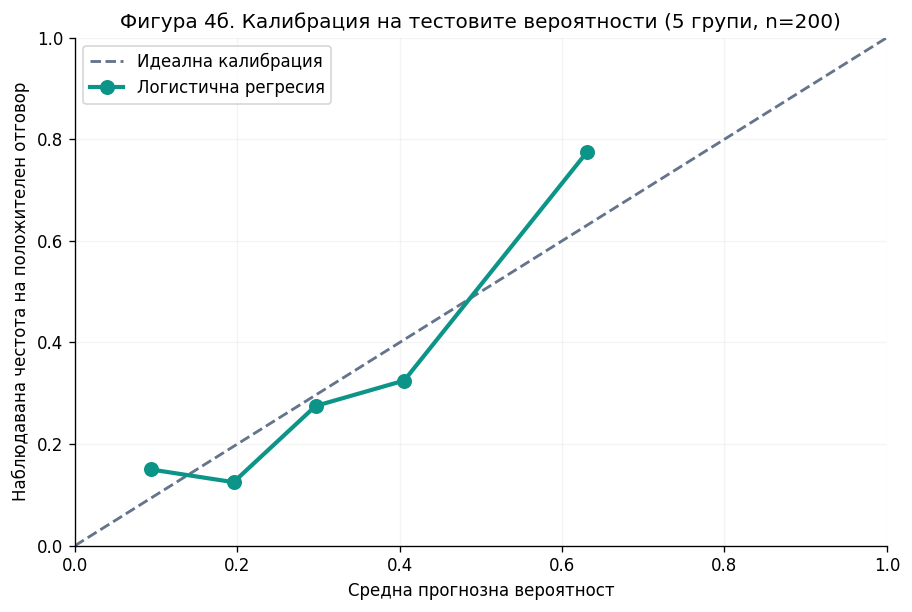

In [11]:
from sklearn.calibration import calibration_curve
frac_positive, mean_prediction = calibration_curve(
    labels, prob_log, n_bins=5, strategy='quantile'
)
fig, ax=plt.subplots(figsize=(7.7,5.2))
ax.plot([0,1],[0,1],ls='--',lw=1.7,color='#64748b',label='Идеална калибрация')
ax.plot(mean_prediction, frac_positive, marker='o',ms=8,lw=2.5,color='#0d9488',
        label='Логистична регресия')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Средна прогнозна вероятност',
       ylabel='Наблюдавана честота на положителен отговор',
       title='Фигура 4б. Калибрация на тестовите вероятности (5 групи, n=200)')
ax.grid(axis='both',alpha=.13)
ax.legend(loc='upper left')
plt.tight_layout();plt.show()

**Извод от Фигура 4б.** Диаграмата е допълнителна проверка на вероятностните прогнози. При бъдещо внедряване тя трябва да се повтори на **нови**, предварително невиждани данни; калибрацията е важна за решения с финансов праг. За настоящата курсова работа основното решение е ранжиране, а не обещание за индивидуално точна вероятност.

## 6. Кои характеристики са свързани с отговора?

Логистичната регресия позволява да разгледаме всяка характеристика **при равни други условия**. Числовите коефициенти отразяват промяна с едно стандартно отклонение (1 SD), а членството сравнява `Yes` с `No`. `Odds ratio` над 1 означава по-висок **шанс**, не пропорционално по-висока **вероятност**. Това са асоциации и не доказват причинен ефект.

В този набор най-ясните положителни сигнали според модела са членството в лоялната програма, посещенията на сайта и броят поръчки. По-голям брой дни от последната покупка е свързан с по-ниска склонност за отговор. Това не означава, че трябва да се ограничаваме само до лоялни клиенти — за ранжирането се използват всички предиктори.


,Променлива,Коефициент,Odds ratio
6,Член на лоялна програма (Yes vs No),+0.896,2.45
0,Посещения (1 SD),+0.611,1.84
1,Поръчки (1 SD),+0.456,1.58
4,Email ангажираност (1 SD),+0.275,1.32
5,Промо афинитет (1 SD),+0.269,1.31
2,Средна стойност (1 SD),+0.137,1.15
3,Дни от покупка (1 SD),-0.566,0.57


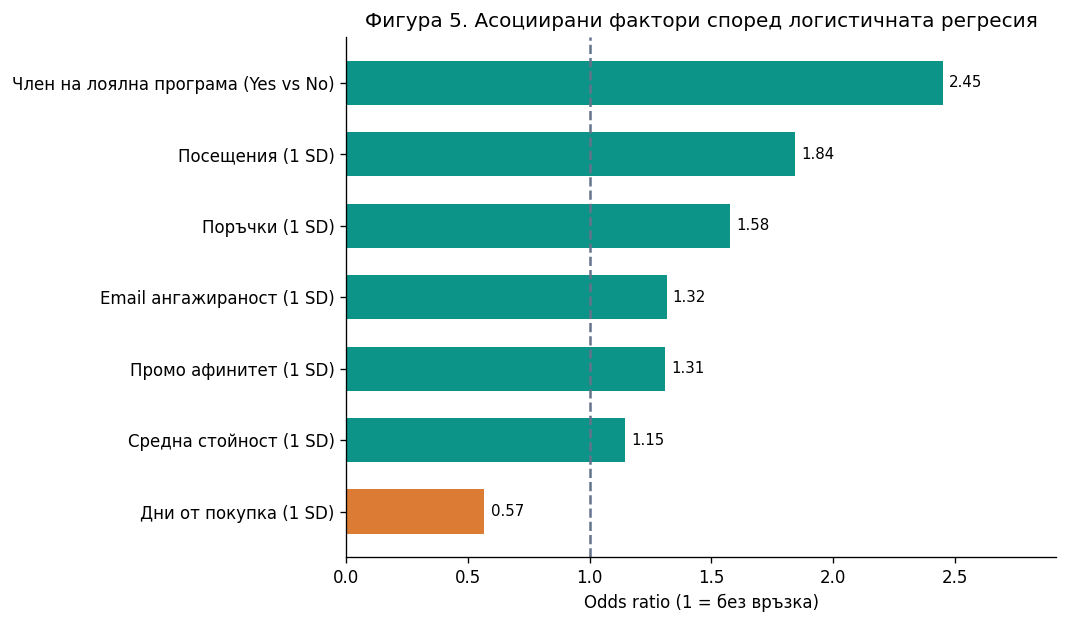

In [12]:
selected_model=models['Логистична регресия']
encoded_names=selected_model.named_steps['prep'].get_feature_names_out()
coefficients=selected_model.named_steps['model'].coef_[0]
coeff_table=(pd.DataFrame({'Променлива':[
    'Посещения (1 SD)','Поръчки (1 SD)','Средна стойност (1 SD)',
    'Дни от покупка (1 SD)','Email ангажираност (1 SD)',
    'Промо афинитет (1 SD)','Член на лоялна програма (Yes vs No)'],
    'Коефициент':coefficients,'Odds ratio':np.exp(coefficients)})
    .sort_values('Odds ratio',ascending=False))
display(coeff_table.style.format({'Коефициент':'{:+.3f}','Odds ratio':'{:.2f}'}))
fig,ax=plt.subplots(figsize=(9,5.3))
t=coeff_table.sort_values('Odds ratio')
colors=['#0d9488' if x>=1 else '#db7b34' for x in t['Odds ratio']]
ax.barh(t['Променлива'],t['Odds ratio'],color=colors,height=.62)
ax.axvline(1,ls='--',color='#64748b')
ax.set(xlabel='Odds ratio (1 = без връзка)',title='Фигура 5. Асоциирани фактори според логистичната регресия')
for i,val in enumerate(t['Odds ratio']): ax.text(val+.025,i,f'{val:.2f}',va='center',fontsize=9)
ax.set_xlim(0,max(t['Odds ratio'])*1.19)
plt.tight_layout();plt.show()

## 7. Избор на таргетираща група

За да симулираме ограничен контактен ресурс, подреждаме **тестовите** клиенти от най-висока към най-ниска прогнозна вероятност. Разглеждаме три работни сценария: 20%, 30% и 40% обхват. Сравняваме с базовата честота **в същата тестова извадка**, за да има еднакъв знаменател.

- **Response rate в групата** = действително отговорили / избрани клиенти.
- **Lift** = response rate в избраната група / response rate в целия тест.
- **Capture rate** = действително отговорили в избраната група / всички действително отговорили в теста.

Правилото **топ 30%** се използва като *примерен капацитет на пилотна кампания*, а не като математически оптимален процент. Ако бюджетът позволява само 20% контакти, именно групата топ 20% е първи избор. Реалният капацитет следва да се определи чрез цена на контакт, марж и очаквана допълнителна стойност.


In [13]:
chosen_probabilities=test_probabilities['Логистична регресия']
ranked=pd.DataFrame({'prob':chosen_probabilities,'observed':y_test.to_numpy()}).sort_values('prob',ascending=False)
base_rate=ranked['observed'].mean()
segment_rows=[]
for share in (.2,.3,.4,.5):
    k=int(round(len(ranked)*share))
    top=ranked.head(k)
    positive=int(top['observed'].sum())
    segment_rows.append({'Дял':share,'Клиенти':k,'Положителни':positive,
                         'Response rate':positive/k,'Lift':(positive/k)/base_rate,
                         'Capture':positive/ranked['observed'].sum(),
                         'Cutoff':top['prob'].iloc[-1]})
segments=pd.DataFrame(segment_rows)
display(segments.style.format({'Дял':'{:.0%}','Response rate':'{:.1%}',
                                'Lift':'{:.2f}×','Capture':'{:.1%}','Cutoff':'{:.3f}'}))

,Дял,Клиенти,Положителни,Response rate,Lift,Capture,Cutoff
0,20%,40,31,77.5%,2.35×,47.0%,0.487
1,30%,60,37,61.7%,1.87×,56.1%,0.393
2,40%,80,44,55.0%,1.67×,66.7%,0.340
3,50%,100,49,49.0%,1.48×,74.2%,0.296


**Фигура 6.** В тестовата извадка топ 30% включват 60 клиента, от които **37** имат исторически положителен отговор. Следователно честотата е **61,7%**, lift **1,87×**, а групата обхваща **56,1%** от общо 66 положителни отговора. Ако изберем топ 20%, честотата се повишава до **77,5%**, но обхватът спада до **47,0%**. Разширението от 20% до 30% добавя още 20 контакта и **6 исторически положителни отговора** (30,0% в допълнителната група).

Това е най-полезното маркетингово сравнение: **по-широк обхват срещу по-малка ефективност на допълнителния контакт**. Резултатите са ретроспективни; изборът на сценарий е проучвателен, а не прогноза за сигурна реална възвръщаемост.


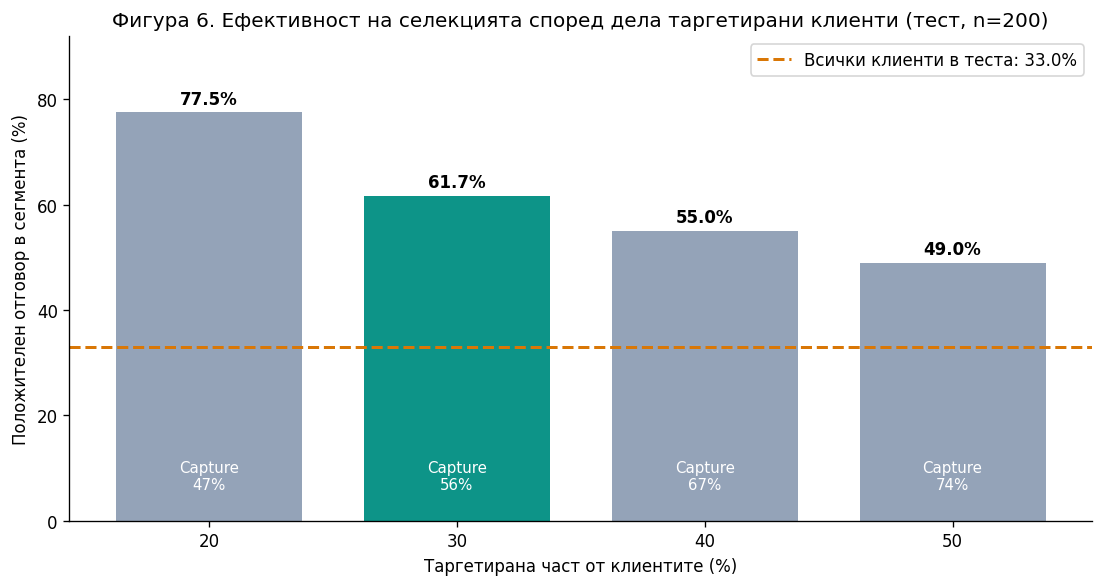

In [14]:
fig,ax=plt.subplots(figsize=(9.3,5))
xs=segments['Дял']*100
bars=ax.bar(xs,segments['Response rate']*100,width=7.5,color=['#94a3b8','#0d9488','#94a3b8','#94a3b8'])
ax.axhline(base_rate*100,color='#d97706',linestyle='--',linewidth=1.8,
           label=f'Всички клиенти в теста: {base_rate:.1%}')
for bar,rate,cap in zip(bars,segments['Response rate'],segments['Capture']):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+1.6,f'{rate:.1%}',ha='center',weight='bold')
    ax.text(bar.get_x()+bar.get_width()/2,6,f'Capture\n{cap:.0%}',ha='center',color='white' if bar.get_height()>35 else '#111827',fontsize=9)
ax.set(title='Фигура 6. Ефективност на селекцията според дела таргетирани клиенти (тест, n=200)',
       xlabel='Таргетирана част от клиентите (%)',ylabel='Положителен отговор в сегмента (%)',
       ylim=(0,92),xticks=xs)
ax.legend(loc='upper right');plt.tight_layout();plt.show()

### Как бих приложила правилото в следваща кампания

1. Определяме допустимите за маркетингов контакт клиенти според приложимото правно основание, предпочитанията им и направените откази от комуникация.
2. Обновяваме седемте характеристики **към дата преди изпращането**; не използваме информация, възникнала след контакта.
3. Оценяваме `P(response = Yes)` за допустимите клиенти и подреждаме резултатите низходящо.
4. Ако предварително определеният капацитет е 30%, избираме първите 30% от **допустимата** аудитория. При по-малък бюджет използваме топ 20%; при разширяване изискваме положителна очаквана икономика на допълнителните контакти.
5. Изпълняваме пилот с контролна група и сравняваме действително постигнатите конверсии и маржове.

**Важно:** историческата база не е списък за автоматично изпращане на новата оферта. За реална кампания е необходим нов допустим за обработване набор с актуални данни.


In [15]:
from sklearn.base import clone
# Демонстрационен production-like refit върху цялата историческа база.
# Не е оценка на качеството: коректните извън-извадкови резултати са по-горе.
final_model=clone(models['Логистична регресия']).fit(X,y)
all_history_prob=final_model.predict_proba(X)[:,1]
scored_history=(pd.DataFrame({'customer_id':df['customer_id'],
                              'propensity_score':all_history_prob})
                .sort_values(['propensity_score','customer_id'],ascending=[False,True]))
selected_count=int(np.ceil(.30*len(scored_history)))
selected_history=scored_history.head(selected_count)
print(f'Илюстративна историческа аудитория: {selected_count} от {len(scored_history)} клиенти (30%).')
print('За реална кампания оценете НОВА актуална клиентска база и приложете филтър за допустим контакт.')

Илюстративна историческа аудитория: 240 от 800 клиенти (30%).
За реална кампания оценете НОВА актуална клиентска база и приложете филтър за допустим контакт.


## 8. Маркетингови препоръки

**Предложение за пилот.** При предварително определен ресурс за 30% от допустимата аудитория използваме логистична регресия за ранжиране на клиентите. Така не разчитаме само на една характеристика, например членство в програма за лоялност.

**Третиране на аудиторията.** На клиенти със скорошни поръчки може да се тества съобщение за допълващ продукт; при висока чувствителност към промоции — ясна оферта с ограничен срок. Това са **хипотези за A/B тест**, не доказани от CSV файла индивидуални предпочитания. В данните липсва информация кои продукти са купували клиентите.

**Измерване на резултата.** Изпращането на офертата само по себе си не е успех. Необходима е контролна група, определена на случаен принцип, без промоционалния стимул и сравнение по конверсия, приход на контакт и **нетен марж след отстъпката**. При възможност се измерва инкременталният ефект, а не само историческият response.

**Последващо развитие.** След пилота проверяваме дали прогнозните вероятности съответстват на реалните честоти, дали моделът остава стабилен и дали допълнителните контакти носят положителен принос.

### Три ограничения, които влияят на решението

1. **Няма дати на характеристиките и кампанията.** Не може да се провери времевата последователност на данните или стабилността в следващ период; техническото избягване на leakage не отстранява този риск.
2. **Няма цена на контакт, размер на отстъпката или марж.** Няма основание да се обявяват 30% за икономически оптимален обхват.
3. **Една историческа кампания, 800 клиента и липса на контролна група.** Предвиждаме склонност към отговор, не доказваме допълнителни продажби вследствие на офертата.

## 9. Заключение

При сравнените конкретни конфигурации **логистичната регресия е предпочетена** за първоначален пилот. Тя позволява разбираемо обяснение на резултатите и показва малко по-добро ранжиране. В тестовата извадка, при илюстративно ограничение до 30% от контактите, получаваме 37 положителни отговора сред 60 избрани клиенти. По-малък бюджет може да оправдае по-тясна, но по-ефективна на контакт група от 20%.

**Решението за ShopDirect:** да използва модела като инструмент за *приоритизиране*, да определи бюджета предварително и да провери икономическия и инкременталния ефект с контролирана кампания. Реалният принос остава за измерване, а не е доказан от наличния CSV.


## 10. Подготовка за защита: кратки отговори със собствена аргументация

**Какъв проблем решаваме?** При ограничен брой маркетингови контакти искаме да изберем клиенти, които според историческите данни са по-склонни да отговорят.

**Защо логистична регресия?** И двата модела са проверени върху едни и същи данни. Логистичната регресия има малко по-добра CV и тестова AUC, а коефициентите ѝ се обясняват лесно. Разликата не е доказано значима.

**Какво е ROC AUC 0,774?** При случайно избрани отговорил и неотговорил клиент моделът поставя по-висока оценка на отговорилия в около 77,4% от случаите. Това не означава „77,4% точност“ или „77,4% шанс всяка прогноза да е вярна“.

**Защо 30%, а не 20%?** 30% е примерен контактен капацитет. Той включва повече от исторически отговорилите, но с по-нисък response rate: 61,7% вместо 77,5%. При строг бюджет бих започнала с 20%. Без маржове не можем да докажем оптимален процент.

**Как избягваме data leakage?** Разделяме данните на train и test преди обучението. `Pipeline` обучава стандартизацията само от train. Но не знаем със сигурност дали историческите характеристики са измерени преди предишната кампания — това е отделен риск.

**Какво означава odds ratio 2,45 за лоялност?** При контрол за останалите признаци моделът показва приблизително 2,45 пъти по-високи *odds*, не 2,45 пъти по-висока вероятност и не доказателство, че членството причинява отговор.

**Защо не използваме праг P≥0,50 за аудиторията?** Праговата класификация отговаря на друг въпрос. При фиксиран бюджет трябва да подредим клиентите по вероятност и да вземем първите N.

**Как ще разберем дали кампанията работи?** С контролна група и показатели за инкрементална конверсия, приходи и нетен марж, а не само с исторически response rate.

## 11. Източници и произход на данните

**Емпирични данни:** `P3_1_campaign_response.csv`, учебен набор, предоставен от преподавателя за казуса P3.1; 800 наблюдения. Данните не се разпространяват повторно с предаваните файлове.

**Методологична документация (проверена на 13.11.2026 г.):**

1. scikit-learn developers. *Common pitfalls and recommended practices* — раздел за data leakage и коректно използване на `Pipeline`. https://scikit-learn.org/stable/common_pitfalls.html
2. scikit-learn developers. *Cross-validation: evaluating estimator performance* — `StratifiedKFold` и процедури за проверка. https://scikit-learn.org/stable/modules/cross_validation.html
3. scikit-learn developers. *Metrics and scoring: quantifying the quality of predictions* — ROC AUC, accuracy и метрики за двоична класификация. https://scikit-learn.org/stable/modules/model_evaluation.html
4. scikit-learn developers. *Probability calibration* — интерпретация на калибрационните криви и Brier score. https://scikit-learn.org/stable/modules/calibration.html
5. scikit-learn developers. *Tuning the decision threshold for class prediction* — разграничаване на класификационен праг от бизнес решение. https://scikit-learn.org/stable/modules/classification_threshold.html

**Бележка:** Използваните външни източници са за методиката. Всички числени резултати в работата са изчислени от предоставения CSV файл чрез публикувания по-горе Python код.
